## 02-EDA Exploratory Data Analysis - Pitt Dataset

We have new datasets from DementiaBank. Now we explore the English - Pitt dataset

In [1]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import re

In [2]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [3]:
path_ad = "../data/TalkBank downloads/Pitt/Dementia/Cookie/"
path_cn = "../data/TalkBank downloads/Pitt/Control/Cookie/"

In [4]:
train_data = {"ad":[], 
              "cn":[]
             }

In [5]:
def line_clean(line):
    """
        Clean line from extra information like "*PAR: ", "\x1530_5640\x15", etc
    """
    result = line
    if result.startswith("*PAR"):
        result = result.replace("*PAR:\t", "")
        result = re.sub(".*", "", result)
        result = re.sub("\[.*\]", "", result)
        result = result.strip("&-+<").strip()
    else:
        result = ""
    return result

s = '*PAR:\tthe scene is <in the> [/] in the kitchen . \x1530_5640\x15\n'
assert line_clean(s) == "the scene is <in the>  in the kitchen ." 

In [6]:
def read_data(path):
    """
        get data from "txt" files from a specified folder (ad/cn)
        returns list of text (strings)
    """
    result = []
    # get only txt files
    files = [item
             for item in os.listdir(path)
             if item.endswith("cha")
            ]
    
    for fname in files:
        print("Processing files =", fname) #, end="\r")
        with open(path + fname, encoding="utf-8") as f:
            lines = f.readlines()
            print("Line counts =", len(lines)) #, end="\r")
            # apply filter to clean text
            lines = [line_clean(line)
                     for line in lines
                     if line.startswith("*PAR")
                    ]
            print("After cleaning, Line counts =", len(lines)) #, end="\r")

            text = "\n".join(lines)
            result.append(text)

    return result



In [7]:
train_data["ad"] = read_data(path_ad)
train_data["cn"] = read_data(path_cn)

Processing files = 001-0.cha
Line counts = 85
After cleaning, Line counts = 10
Processing files = 001-2.cha
Line counts = 125
After cleaning, Line counts = 13
Processing files = 003-0.cha
Line counts = 172
After cleaning, Line counts = 23
Processing files = 005-0.cha
Line counts = 73
After cleaning, Line counts = 9
Processing files = 005-2.cha
Line counts = 92
After cleaning, Line counts = 7
Processing files = 007-1.cha
Line counts = 105
After cleaning, Line counts = 13
Processing files = 007-3.cha
Line counts = 85
After cleaning, Line counts = 9
Processing files = 010-0.cha
Line counts = 186
After cleaning, Line counts = 22
Processing files = 010-1.cha
Line counts = 201
After cleaning, Line counts = 27
Processing files = 010-2.cha
Line counts = 208
After cleaning, Line counts = 32
Processing files = 010-3.cha
Line counts = 128
After cleaning, Line counts = 17
Processing files = 010-4.cha
Line counts = 92
After cleaning, Line counts = 9
Processing files = 014-2.cha
Line counts = 161
Af

In [8]:
# double check data
assert len(train_data["ad"]) == 306
assert len(train_data["cn"]) == 243
assert train_data["ad"][0].startswith("mhm")
assert train_data["ad"][1].startswith("mhm")
assert train_data["cn"][0].startswith("the scene is <in the>")
assert train_data["cn"][1].startswith("oh I see the sink is running over")
print("Passed")

Passed


In [9]:
# take a look at the data
print(train_data["ad"][0][:100])

mhm .
alright .
there's &-um a young boy that's getting a cookie jar .
and it  he's &-uh in bad shap


In [10]:
# take a look at the data
print(train_data["cn"][0][:100])

the scene is <in the>  in the kitchen .
the mother is wiping dishes and the water is running on the 


In [11]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words        
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(WordCloud().process_text(text).items(), 
                    key=lambda item: item[1],
                    reverse=True
                   )
    
    
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

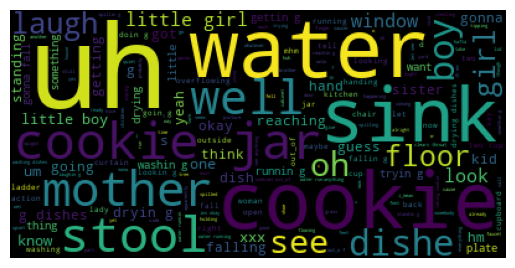

[('uh', 714), ('water', 274), ('cookie', 257), ('sink', 232), ('cookie jar', 217), ('stool', 211), ('mother', 202), ('well', 193), ('dishe', 192), ('boy', 186), ('oh', 159), ('see', 158), ('laugh', 140), ('floor', 123), ('girl', 121), ('little girl', 108), ('window', 103), ('look', 103), ('little boy', 103), ('one', 101), ('know', 99), ('um', 96), ('xxx', 91), ('kid', 79), ('s', 78), ('hand', 75), ('going', 74), ('got', 74), ('g', 73), ('dryin g', 70), ('okay', 69), ('guess', 68), ('reaching', 66), ('g dishes', 65), ('sister', 63), ('think', 62), ('standing', 61), ('falling', 60), ('yeah', 58), ('gonna', 57), ('dish', 55), ('getting', 54), ('hm', 53), ('runnin g', 53), ('little', 52), ('washin g', 52), ('gettin g', 52), ('want', 50), ('thing', 49), ('plate', 49)]


In [12]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(train_data["ad"])
print(ad_top_words[:50])
ad_top_words_set = set([w
                        for w, count in ad_top_words[:200]
                       ])

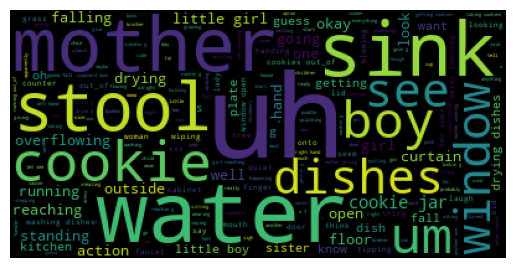

[('uh', 527), ('water', 247), ('mother', 243), ('sink', 242), ('stool', 234), ('cookie', 227), ('boy', 184), ('um', 184), ('window', 167), ('dishes', 164), ('see', 163), ('cookie jar', 162), ('okay', 116), ('standing', 113), ('action', 110), ('look', 108), ('little girl', 107), ('reaching', 104), ('open', 101), ('floor', 98), ('girl', 96), ('one', 92), ('curtain', 91), ('falling', 89), ('hand', 83), ('well', 80), ('overflowing', 79), ('drying', 78), ('outside', 77), ('going', 72), ('running', 71), ('little boy', 67), ('plate', 65), ('g', 62), ('oh', 57), ('dish', 56), ('sister', 56), ('getting', 55), ('fall', 54), ('know', 54), ('drying dishes', 53), ('kitchen', 49), ('want', 49), ('guess', 49), ('s', 44), ('washing dishes', 44), ('looking', 43), ('out_of', 43), ('two cups', 43), ('counter', 42)]


In [13]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud(train_data["cn"])
print(cn_top_words[:50])
cn_top_words_set = set([w
                        for w, count in cn_top_words[:200]
                       ])

In [14]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)


AD unique words =
 {'spillin g', 'hafta', 'somethin g', 'wash', 'dishe', 'g dishes', 'young', 'laughin g', 'u', 'th', 'doin g', 'taking cookie', 'upset', 'still', 'three', 'i_mean', 'already', 'sh', 'th em', 'ladder', 'good', 'somebody', 'water spilling', 'time', 'spilled', 'out_o f', 'tryin g', 'part', 'comin g', 'call', 'wa', 'way', 't', 'f', 'yes', 'huh', 'turn', 'even', 'fell', 'spigot', 'hurt', 'whatever', 'water run', 'take', 'you_know', 'c', 'coming', 'foot', 'inv okay', 'two cup', 'yet'}
----------------
CN unique words =
 {'nose', 'shrubbery', 'another one', 'wearing', 'putting', 'bushes', 'really', 'socks', 'two cups', 'breeze', 'lip', 'dress', 'laughing', 'o f', 'sigh', 'puddle', 'full', 'almost', 'giving', 'asking', 'turned', 'climbing', 'nothing', 'summer', 'dishes', 'stepping', 'window open', 'splashing', 'right hand', 'attention', 'child', 'mother washing', 'pretty', 'short', 'mean', 'saying', 'growing', 'girl reaching', 'running out_of', 'taking cookies', 'left hand', '

In [15]:
# combine data into a dataframe, for export to a csv for further processing
train_dict = {
    "text": [],  # the transcript
    "target": [] # the target: positive (AD), negative (CN)
}
for item in train_data["ad"]:
    train_dict["text"].append(item)
    train_dict["target"].append("AD")

for item in train_data["cn"]:
    train_dict["text"].append(item)
    train_dict["target"].append("CN")

print("Text count =", len(train_dict["text"]))
print("Target count =", len(train_dict["target"]))

Text count = 549
Target count = 549


In [16]:
train_df = pd.DataFrame(train_dict)
print(len(train_df))
train_df.head()

549


,text,target
0,mhm .\nalright .\nthere's &-um a young boy tha...,AD
1,mhm .\nthere's a young boy &-uh going in a coo...,AD
2,here's a cookie jar .\nand the lid is off the ...,AD
3,the boy is slipping off the stool .\nhe's tryi...,AD
4,okay ‡ he's fallin(g) off a chair .\nshe's &-...,AD


In [17]:
train_df.describe()

,text,target
count,549,549
unique,549,2
top,mhm .\nalright .\nthere's &-um a young boy tha...,AD
freq,1,306


We can see we have total of 549 examples, with 306 (about 55%) positive (AD) and 243 (about 45%) negative (CN). The train_set is relatively balanced, although there are slightly more examples with positive labels. 

### Now we can split the data into train and dev set
We can split in to (80-20)-15 sets (train, dev, test)

In [18]:

# X_train, X_dev, y_train, y_dev  = train_test_split(train_df["text"], 
#                                                    train_df["target"],
#                                                    test_size=0.15,
#                                                    random_state=42
#                                                   )
# first, split between train and test
print("Dataset len =", len(train_df))
X_train, X_test, y_train, y_test  = train_test_split(train_df["text"], 
                                                     train_df["target"],
                                                     test_size=0.15,
                                                     random_state=42
                                                    )

# then, split between train and dev
X_train, X_dev, y_train, y_dev  = train_test_split(X_train, 
                                                     y_train,
                                                     test_size=0.2,
                                                     random_state=42
                                                    )

print("X_train len =", len(X_train))
print("y_train len =", len(y_train))
print("X_dev len =", len(X_dev))
print("y_dev len =", len(y_dev))

print("X_test len =", len(X_test))
print("y_test len =", len(y_test))


Dataset len = 549
X_train len = 372
y_train len = 372
X_dev len = 94
y_dev len = 94
X_test len = 83
y_test len = 83


In [19]:
# write to csv
path = "../data/splits/"
train_set_df = pd.DataFrame({"text":X_train, 
                             "target":y_train
                            })

dev_set_df = pd.DataFrame({"text":X_dev, 
                           "target":y_dev
                          })

test_set_df = pd.DataFrame({"text":X_test, 
                           "target":y_test
                          })


In [20]:
train_set_df.head()

,text,target
390,little boy getting in the cookie jar .\nand th...,CN
542,well ‡ the sink's overflowing .\nand &-uh the ...,CN
95,"this picture ?\nwell, there's a kid on a stool...",AD
335,everything I see in action or everything I +.....,CN
247,there's a little boy or> there's a little gir...,AD


In [21]:
dev_set_df.head()

,text,target
182,whew &=laughs .\nuh do I hafta use my &-uh my...,AD
498,okay .\nthe woman fouled up and left the spigo...,CN
533,"everything, not things that are just bad right...",CN
71,the boy is &-uh &+d after the cookie jar for h...,AD
56,(.) that &=clears:throat\nand and she's &-uh...,AD


In [22]:
test_set_df.head()

,text,target
195,I see a boy getting into the cookie jar .\nand...,AD
79,okay .\nthe little boy is snitching a cookie w...,AD
479,he's falling off the stool .\nthe water's over...,CN
109,a little boy is gettin(g) himself some cookies...,AD
473,mother's dryin(g) the dishes .\nJunior's in th...,CN


In [23]:
print("Writing to csv files...")

train_set_df.to_csv(path + "train_pitt.csv",
                   index=False)
dev_set_df.to_csv(path + "dev_pitt.csv",
                 index=False)
test_set_df.to_csv(path + "test_pitt.csv",
                 index=False)

print("Completed")

Writing to csv files...
Completed
